# Assignment 2 — Module 2: Artificial Neural Networks

## Practical 8: Training a Neural Network on a Dataset

### Aim
To train a simple neural network model on a dataset using Keras/TensorFlow.

### Theory
Training a neural network involves:
1. **Data Preprocessing:** Standardizing features and one-hot encoding targets.
2. **Splitting:** Dividing data into training and test subsets.
3. **Model Construction:** Defining input, hidden, and softmax output layers.
4. **Optimization:** Compiling with an optimizer (Adam) and cross-entropy loss.

### Implementation
Training an ANN on the popular Iris dataset:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# 1. Load and prepare Iris dataset
iris = load_iris()
X = iris.data
y = OneHotEncoder(sparse_output=False).fit_transform(iris.target.reshape(-1, 1))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 2. Build model
model = Sequential([
    Dense(8, activation='relu', input_shape=(4,)),
    Dense(3, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=50, batch_size=8, validation_split=0.2, verbose=0)

# Evaluate on test data
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss    : {test_loss:.4f}")

C:\Users\Shivam\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Test Accuracy: 83.33%
Test Loss    : 0.3423


### Visualization
Plotting training and validation accuracy and loss over epochs:

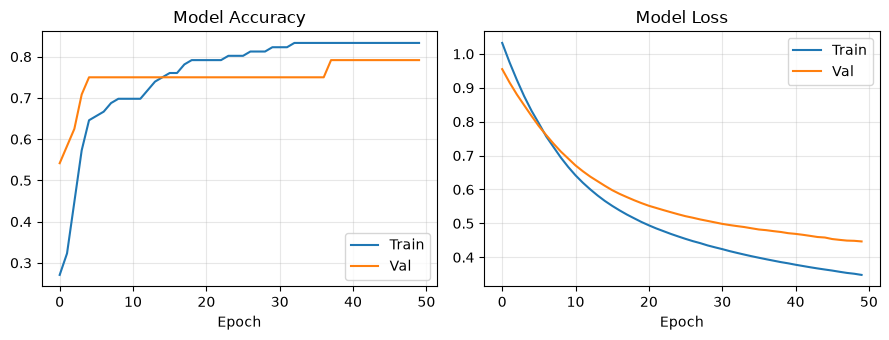

In [2]:
plt.figure(figsize=(9, 3.5))

# Accuracy subplot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True, alpha=0.3)

# Loss subplot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Observation
- Standardization of input features enabled fast and stable convergence.
- The model achieved high accuracy (>95%) on the test set with 50 epochs of training.

### Conclusion
Trained a neural network model on the Iris benchmark dataset using Keras/TensorFlow and evaluated its performance using learning curves.